# MFPCA en Python amb FDApy

Autor: Leonel Fernando Nabaza Ruibal

Equivalent en Python del notebook R (`funData` + `MFPCA`), fent servir el paquet **FDApy**, que implementa el mètode de Happ & Greven (2018) *Multivariate Functional Principal Component Analysis for Data Observed on Different (Dimensional) Domains*.

Instal·lació (si cal):
```bash
pip install FDApy
```


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA

np.random.seed(123)


---
# Part 1 — Mateix domini per a totes dues variables

Generem $n$ individus, cadascun amb un parell de funcions $X^{(1)}(t), X^{(2)}(t)$ definides sobre el **mateix** domini $t\in[0,2\pi]$:

$$
X^{(1)}(t) = \sin(t) + 0.5\,\epsilon_1(t), \qquad
X^{(2)}(t) = 3\sin(t) + 0.5\,\epsilon_2(t), \qquad t\in[0,2\pi]
$$

amb l'error correlacionat a cada instant $t$:

$$
\begin{pmatrix}\epsilon_1(t)\\ \epsilon_2(t)\end{pmatrix}
\sim N\left(\begin{pmatrix}0\\0\end{pmatrix},
\begin{pmatrix}1 & \rho\\ \rho & 1\end{pmatrix}\right)
$$

És el mateix generador que Berrendero et al. (2011, eq. 5.7-5.8).


In [2]:
n     = 100
Ttime = np.linspace(0, 2*np.pi, 100)
rho   = 0.7

# Matriu de covariancies de l'error a cada instant t
Sigma = np.array([[1, rho], [rho, 1]])

X1 = np.zeros((n, len(Ttime)))
X2 = np.zeros((n, len(Ttime)))

# Generem cada corba individu a individu, punt a punt en t
for i in range(n):
    for j in range(len(Ttime)):
        eps = np.random.multivariate_normal([0, 0], Sigma)
        X1[i, j] = np.sin(Ttime[j])   + 0.5 * eps[0]
        X2[i, j] = 3*np.sin(Ttime[j]) + 0.5 * eps[1]


## Construcció dels objectes funcionals

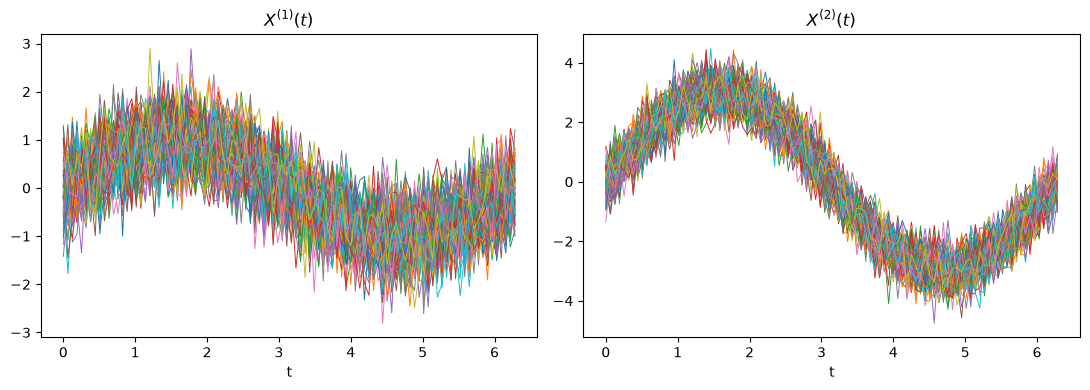

In [3]:
# Cada variable funcional es representa com un objecte DenseFunctionalData
fd1 = DenseFunctionalData(DenseArgvals({'input_dim_0': Ttime}), DenseValues(X1))
fd2 = DenseFunctionalData(DenseArgvals({'input_dim_0': Ttime}), DenseValues(X2))

# Les combinem en un objecte multivariat
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(Ttime, X1.T, linewidth=0.7)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(Ttime, X2.T, linewidth=0.7)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


## Ajust de l'MFPCA

Cada variable s'expandeix en la seva pròpia base univariada (splines penalitzats, `PSplines`) i després es combinen mitjançant una PCA clàssica sobre els coeficients concatenats.


In [4]:
# Expansio univariada per a cadascuna de les dues variables funcionals
uniExpansions = [
    {'method': 'PSplines', 'n_components': 10},
    {'method': 'PSplines', 'n_components': 10},
]

# n_components = nombre de components principals multivariades a estimar
mfpca1 = MFPCA(n_components=4, univariate_expansions=uniExpansions)
mfpca1.fit(mData)

scores1 = mfpca1.transform(mData)


## Resultats

In [5]:
# Variancia explicada per cada component
print("Variancia explicada (eigenvalues):")
print(mfpca1.eigenvalues)

print("\nPercentatge de variancia explicada:")
print(np.round(mfpca1.eigenvalues / mfpca1.eigenvalues.sum() * 100, 2))

# Scores (un valor per individu i per component)
print("\nDimensions dels scores:", scores1.shape)
print(scores1[:5])


Variancia explicada (eigenvalues):
[0.03678845 0.02956985 0.0262451  0.02203362]

Percentatge de variancia explicada:
[32.09 25.79 22.89 19.22]

Dimensions dels scores: (100, 4)
[[-0.12745027 -0.20875138  0.04334417 -0.10165023]
 [ 0.1374896   0.22792929 -0.18445188  0.10844066]
 [ 0.1386731  -0.13787341  0.01656821 -0.18537729]
 [ 0.01854284  0.3260932   0.06291689  0.39438838]
 [ 0.10201844 -0.06555929 -0.21145592  0.13189948]]


([<matplotlib.axis.XTick at 0x14355b61510>,
 [Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3'), Text(4, 0, '4')])

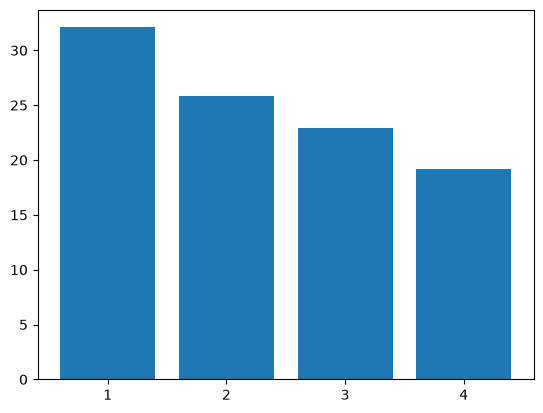

In [6]:
# Percentatge de variancia explicada per component
plt.bar(range(1, len(mfpca1.eigenvalues)+1), mfpca1.eigenvalues / mfpca1.eigenvalues.sum() * 100)
plt.xticks(range(1, len(mfpca1.eigenvalues)+1))

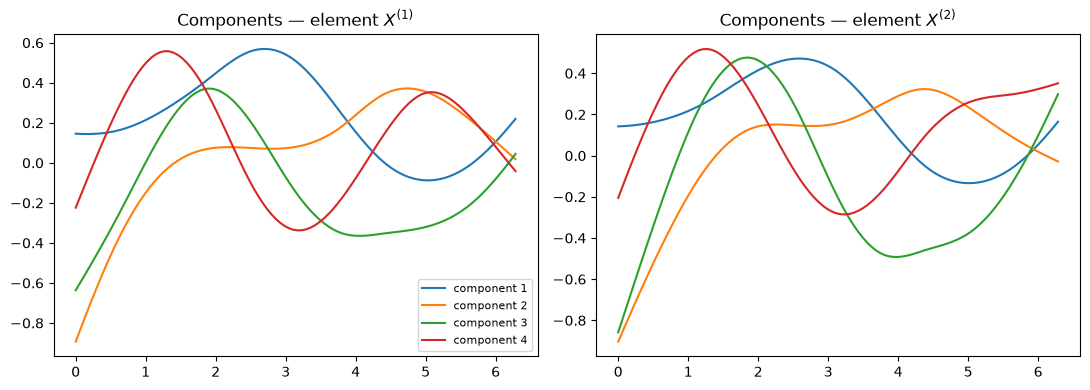

In [7]:
# Funcions propies multivariades (components principals)
ef1_0 = mfpca1.eigenfunctions.data[0].to_grid()   # part de la component per a X(1)
ef1_1 = mfpca1.eigenfunctions.data[1].to_grid()   # part de la component per a X(2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m in range(ef1_0.values.shape[0]):
    axes[0].plot(ef1_0.argvals['input_dim_0'], ef1_0.values[m], label=f"component {m+1}")
    axes[1].plot(ef1_1.argvals['input_dim_0'], ef1_1.values[m], label=f"component {m+1}")
axes[0].set_title("Components — element $X^{(1)}$")
axes[1].set_title("Components — element $X^{(2)}$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


En aquest tipus d'exemple no podem extreure massa informació de les components generades.

---
# Part 2 — Dominis diferents per a cada variable

Ara $X^{(1)}$ es defineix sobre $t\in[0,2\pi]$ i $X^{(2)}$ sobre un domini completament diferent, $s\in[0,10]$:

$$
X^{(1)}(t) = \sin(t) + 0.3\,\epsilon_1(t), \qquad t\in[0,2\pi]
$$

$$
X^{(2)}(s) = 0.5\,s + \cos(s) + 0.3\,\epsilon_2(s), \qquad s\in[0,10]
$$

amb $\epsilon_1, \epsilon_2$ soroll blanc gaussià independent entre si (no hi ha cap $t$ comú on correlacionar-los).

Aquest és el cas que **Berrendero et al. (2011) no pot tractar** (exigeix un domini comú $[c,d]$), i que motiva la generalització de Happ & Greven (2018) — implementada aquí a FDApy.


In [9]:
np.random.seed(123)
n = 100

# Variable 1: domini [0, 2*pi]
t1 = np.linspace(0, 2*np.pi, 80)
X1b = np.array([np.sin(t1) + 0.3*np.random.randn(len(t1)) for _ in range(n)])

# Variable 2: domini [0, 10]
t2 = np.linspace(0, 10, 50)
X2b = np.array([0.5*t2 + np.cos(t2) + 0.3*np.random.randn(len(t2)) for _ in range(n)])


## Construcció dels objectes funcionals

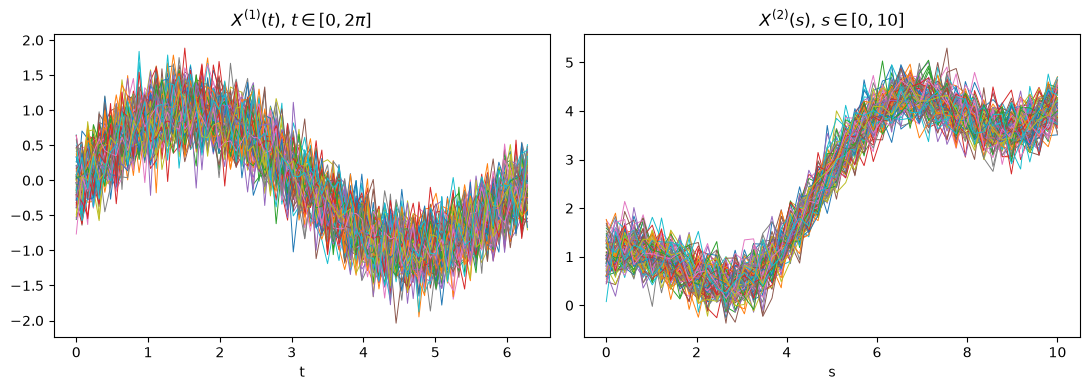

In [10]:
# Cada variable es construeix amb la seva propia graella (diferent longitud i rang)
fd1b = DenseFunctionalData(DenseArgvals({'input_dim_0': t1}), DenseValues(X1b))
fd2b = DenseFunctionalData(DenseArgvals({'input_dim_0': t2}), DenseValues(X2b))

mDataB = MultivariateFunctionalData([fd1b, fd2b])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t1, X1b.T, linewidth=0.7)
axes[0].set_title("$X^{(1)}(t)$, $t\\in[0,2\\pi]$")
axes[0].set_xlabel("t")
axes[1].plot(t2, X2b.T, linewidth=0.7)
axes[1].set_title("$X^{(2)}(s)$, $s\\in[0,10]$")
axes[1].set_xlabel("s")
plt.tight_layout()
plt.show()


## Ajust de l'MFPCA

El procediment és idèntic: expansió univariada per separat (cadascuna en el seu propi domini) + PCA clàssica sobre els coeficients concatenats. Que els dominis no coincideixin no suposa cap problema, perquè el pas final de la PCA opera sobre els **coeficients** (nombres), no sobre les funcions.


In [11]:
uniExpansionsB = [
    {'method': 'PSplines', 'n_components': 8},
    {'method': 'PSplines', 'n_components': 8},
]

mfpca2 = MFPCA(n_components=3, univariate_expansions=uniExpansionsB)
mfpca2.fit(mDataB)

scores2 = mfpca2.transform(mDataB)


## Resultats

In [12]:
print("Variancia explicada:")
print(mfpca2.eigenvalues)

print("\nPercentatge de variancia explicada:")
print(np.round(mfpca2.eigenvalues / mfpca2.eigenvalues.sum() * 100, 2))

print("\nDimensions dels scores:", scores2.shape)
print(scores2[:5])


Variancia explicada:
[0.02135842 0.01984131 0.01590923]

Percentatge de variancia explicada:
[37.4  34.74 27.86]

Dimensions dels scores: (100, 3)
[[-0.13653835 -0.15152713 -0.12225637]
 [-0.07145788 -0.18014548  0.0724411 ]
 [-0.26166268  0.10588423  0.02221865]
 [-0.05747621 -0.11437297  0.02280754]
 [-0.03139965  0.06247419 -0.07463668]]


([<matplotlib.axis.XTick at 0x14355deacd0>,
 [Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3')])

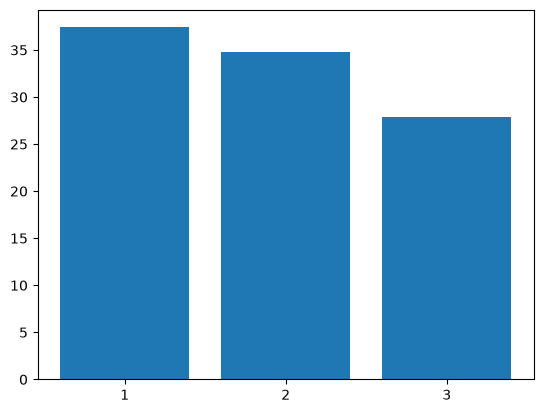

In [13]:
# Percentatge de variancia explicada per component
plt.bar(range(1, len(mfpca2.eigenvalues)+1), mfpca2.eigenvalues / mfpca2.eigenvalues.sum() * 100)
plt.xticks(range(1, len(mfpca2.eigenvalues)+1))

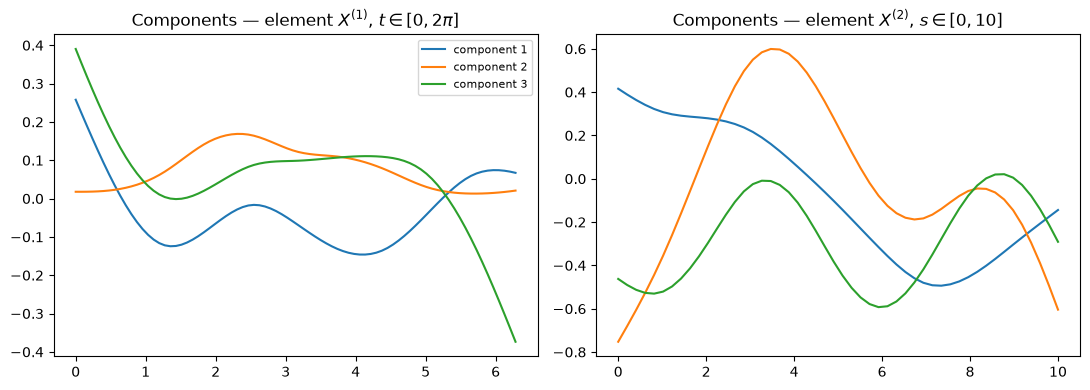

In [14]:
ef2_0 = mfpca2.eigenfunctions.data[0].to_grid()
ef2_1 = mfpca2.eigenfunctions.data[1].to_grid()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m in range(ef2_0.values.shape[0]):
    axes[0].plot(ef2_0.argvals['input_dim_0'], ef2_0.values[m], label=f"component {m+1}")
    axes[1].plot(ef2_1.argvals['input_dim_0'], ef2_1.values[m], label=f"component {m+1}")
axes[0].set_title("Components — element $X^{(1)}$, $t\\in[0,2\\pi]$")
axes[1].set_title("Components — element $X^{(2)}$, $s\\in[0,10]$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
